# Unsupervised learning: groups without names

<div class="roadmap"><div class="rm-sofar"><span>So far</span>A program learns if its performance at a task improves with experience.</div><div class="rm-question"><b>What can be found in data when nobody says what to look for?</b><span>Clustering: k-means puts the hexagons into K groups with similar counts. No label is used.</span></div><div class="rm-steps"><div class="rm-step"><b>k-means</b><span>centres, nearest centre, move, repeat</span></div><div class="rm-step"><b>Groups on the map</b><span>three groups, without names</span></div><div class="rm-step"><b>How many groups?</b><span>the elbow method</span></div><div class="rm-step"><b>Groups and labels</b><span>who names a group?</span></div></div></div>

On this page the land-use label is put aside. All the method sees is the 16 counts of every hexagon.

## 1. How k-means works

Clustering groups observations so that those within a group are as similar as possible and those of different groups as dissimilar as possible. The best-known method is **k-means**, and it needs one number from us: K, the number of groups. It then repeats two steps.

1. Put every hexagon into the group whose centre is nearest.
2. Move every centre to the average of its group.

It stops when no hexagon changes its group. The slider shows these steps for two of the 16 counts, because two counts can be drawn. At the start the three centres are three hexagons picked at random.

In [10]:
two_counts = X[:, [FEATURES.index("car"), FEATURES.index("play")]]          # parking and fuel, playgrounds: two counts that can be drawn


def kmeans_steps(points, k=3, steps=8, seed=3):
    """k-means written out: returns, for every step, the centres and the group of every point."""
    centres = points[np.random.default_rng(seed).choice(len(points), k, replace=False)]
    history = []
    for _ in range(steps):
        group = np.argmin(((points[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2), axis=1)      # step 1: the nearest centre
        history.append((centres.copy(), group))
        centres = np.array([points[group == g].mean(axis=0) if (group == g).any() else centres[g] for g in range(k)])   # step 2: move the centres
    return history


steps_2d = kmeans_steps(two_counts)
print("hexagons that change their group from one step to the next:",
      [int((steps_2d[i][1] != steps_2d[i - 1][1]).sum()) for i in range(1, len(steps_2d))])

hexagons that change their group from one step to the next: [244, 34, 18, 10, 5, 2, 0]


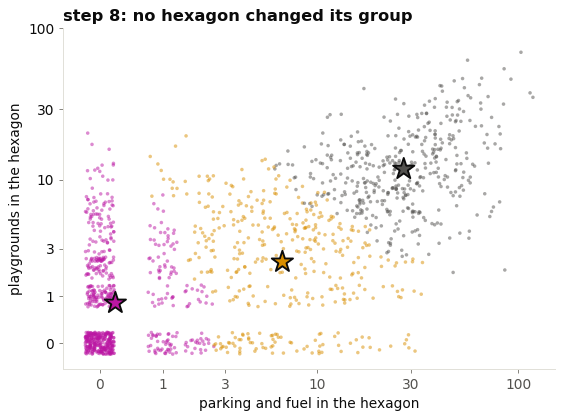

In [11]:
def draw_step(i):
    centres, group = steps_2d[i]
    fig, ax = plt.subplots(figsize=(6.4, 4.8))
    P = h.spread(two_counts, 0.16)
    ax.scatter(P[:, 0], P[:, 1], s=8, color=[h.CLUSTER_COLORS[g] for g in group], alpha=0.5, linewidths=0)
    ax.scatter(centres[:, 0], centres[:, 1], s=320, marker="*", color=[h.CLUSTER_COLORS[g] for g in range(len(centres))], edgecolor=h.INK, linewidths=1.5, zorder=5)
    h.count_ticks(ax, "x", (0, 1, 3, 10, 30, 100)), h.count_ticks(ax, "y", (0, 1, 3, 10, 30, 100))
    ax.set_xlabel("parking and fuel in the hexagon"), ax.set_ylabel("playgrounds in the hexagon")
    changed = int((group != steps_2d[i - 1][1]).sum()) if i else None
    ax.set_title(f"step {i + 1}: every hexagon joins its nearest centre (star)" if i == 0 else
                 f"step {i + 1}: {changed} hexagons changed their group" if changed else f"step {i + 1}: no hexagon changed its group")
    fig.tight_layout()
    return fig


fig = draw_step(len(steps_2d) - 1)
plt.show()
if SAVE:
    h.frames(draw_step, range(len(steps_2d)), "kmeans_steps")

<div class="frames" data-name="kmeans_steps" data-prefix="step" data-first="1"></div>

*k-means on two counts, step by step. The stars are the centres. The colours tell the groups apart and have no other meaning.*

## 2. Three groups on the map

Now all 16 counts are used, and K is set to 3. The map on the left shows the groups that k-means found. The map on the right shows the land-use label, which k-means never saw.

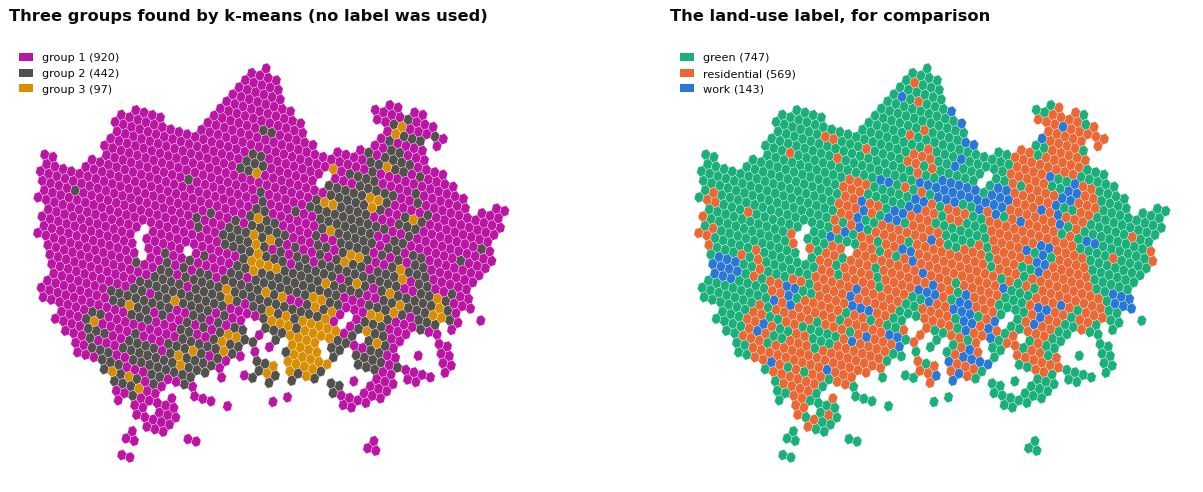

In [12]:
Zk = StandardScaler().fit_transform(X)                 # every count on the same scale, so that no count outweighs the others
KS = list(range(2, 9))
kmeans = {k: KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Zk) for k in KS}
groups = kmeans[3].labels_

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_clusters(hexes, groups, ax=axes[0], title="Three groups found by k-means (no label was used)")
h.map_classes(hexes, y, ax=axes[1], title="The land-use label, for comparison", places=False)
plt.tight_layout()
plt.show()


def draw_k(k):
    fig, ax = plt.subplots(figsize=(8.6, 6))
    h.map_clusters(hexes, kmeans[k].labels_, ax=ax, title=f"k-means with K = {k}")
    return fig


if SAVE:
    h.frames(draw_k, KS, "kmeans")

The groups form patches on the map although k-means was given no coordinates: hexagons with similar counts tend to lie next to each other (step 4 puts a number on this). With another K the same hexagons fall into other groups; move the slider.

<div class="frames" data-name="kmeans" data-labels="K = 2|K = 3|K = 4|K = 5|K = 6|K = 7|K = 8"></div>

*The groups of k-means for K from 2 to 8.*

## 3. How many groups?

Nothing in the data says what K should be. The **elbow method** of part 1 of the lecture runs k-means for several values of K and plots, for each, how far the hexagons lie from the centre of their group (the within-cluster sum of squares). The value falls with every added group; one looks for the K after which it falls only slowly.

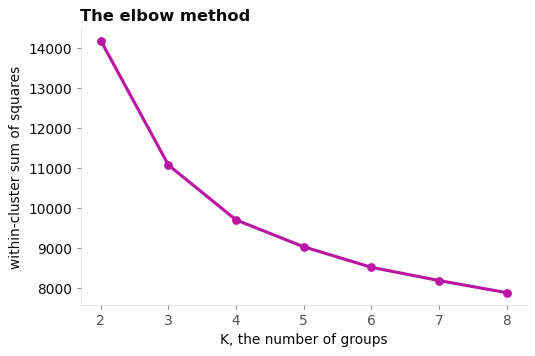

fall of the sum of squares with each added group: {'2 to 3': '22%', '3 to 4': '12%', '4 to 5': '7%', '5 to 6': '6%', '6 to 7': '4%', '7 to 8': '4%'}


In [13]:
wcss = pd.Series({k: kmeans[k].inertia_ for k in KS})
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(wcss.index, wcss.values, "o-", color=h.ACCENT, lw=2.5)
ax.set_xlabel("K, the number of groups")
ax.set_ylabel("within-cluster sum of squares")
ax.set_title("The elbow method")
plt.show()
print("fall of the sum of squares with each added group:", {f"{k - 1} to {k}": f"{1 - wcss[k] / wcss[k - 1]:.0%}" for k in KS[1:]})
h.note("elbow", {int(k): round(float(1 - wcss[k] / wcss[k - 1]), 3) for k in KS[1:]}, SAVE)

> **What did we just see?** The third group reduces the sum of squares by 22%, the fourth by 12%, the fifth by 7%, and every later group by 6% or less. The curve bends between K = 3 and K = 4 and has no sharp elbow, which is common with real data. The elbow method therefore gives a range, and the choice within the range depends on what the groups are for. We keep K = 3, because the land-use label has three classes and the next step compares the groups with it.

## 4. Groups and labels: who names a group?

k-means returns group 1, group 2 and group 3. It does not say what they are. The table counts, for each group, how many of its hexagons carry each land-use label.

In [14]:
table = pd.crosstab(pd.Series(groups + 1, name="group"), pd.Series(y, name="land use"))
table["hexagons"] = table.sum(axis=1)
table["median POIs"] = pd.Series(hexes["poi_total"].to_numpy()).groupby(groups + 1).median().astype(int)      # points of interest in a typical hexagon of the group
named = table[CLASSES].idxmax(axis=1)                       # the most frequent land use of each group
agree = float((named.reindex(groups + 1).to_numpy() == y).mean())
print(table.to_string())
print("\nmost frequent land use of each group:", named.to_dict())
print(f"If every group is named after its most frequent land use, {agree:.0%} of the hexagons get their own label (always answering 'green': {(y == 'green').mean():.0%}).")
same_group = np.mean([np.mean(groups[W[i].indices] == groups[i]) for i in range(len(groups)) if W[i].nnz])
group_chance = (pd.Series(groups).value_counts(normalize=True) ** 2).sum()
print(f"A hexagon shares its group with {same_group:.0%} of its neighbours (if the groups were scattered at random: {group_chance:.0%}).")
h.note("clusters", {"named": {int(k): v for k, v in named.items()}, "agree": round(agree, 3), "same_group": round(float(same_group), 2),
                    "chance": round(float(group_chance), 2)}, SAVE)

land use  green  residential  work  hexagons  median POIs
group                                                    
1           670          184    66       920            4
2            73          314    55       442           69
3             4           71    22        97          242

most frequent land use of each group: {1: 'green', 2: 'residential', 3: 'residential'}
If every group is named after its most frequent land use, 72% of the hexagons get their own label (always answering 'green': 51%).


A hexagon shares its group with 73% of its neighbours (if the groups were scattered at random: 49%).


> **What did we just see?** Group 1 holds 920 hexagons, of which 670 are green. Group 2 is mostly residential. Group 3, with 97 hexagons, is mostly residential too, and no group is mostly work. k-means therefore did not find the three land uses. The last column shows what it found: a typical hexagon has 4 points of interest in group 1, 69 in group 2 and 242 in group 3. The groups are three levels of activity.
>
> Two points follow. First, the groups come without names. To name them we needed the land-use label, which is an answer from outside the counts, and even then only 72% of the hexagons receive their own label (51% if every hexagon is called green). Second, a clustering answers the question that the features pose, here *how much is there in a hexagon?*, and that need not be the question we have in mind. The page on supervised learning gives the method the answers.
>
> The last printed line supports what the maps showed: a hexagon shares its group with 73% of its neighbours, against 49% for groups scattered at random, although k-means never saw a coordinate.